<a href="https://colab.research.google.com/github/chenjeraichantelle-gif/11-17-in-class-assignment/blob/main/DTSC_4050/Assignments/DTSC_4050_Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — Assignment 3: Estimation & Hypothesis Testing
## Total: 125 Points

This assignment is based on the course lessons on **Estimation** and **Hypothesis Testing**.

### Topics
- Parameter vs. statistic and sampling variability
- Percentiles, quartiles, and descriptive estimation
- Bootstrapping and bootstrap distributions
- Confidence intervals
- Null and alternative hypotheses
- Test statistics
- Simulation under the null hypothesis
- Simulation-based p-values
- Statistical significance
- Type I and Type II errors

### Instructions
- Complete all questions and code cells.
- Write interpretations in complete sentences where requested.
- Use **α = 0.05** unless otherwise specified.
- All graphs must have meaningful titles and axis labels.
- Run all cells before submitting the notebook.
- Scores will be deducted for notebooks without output cells.

## Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(4050)

# Section 1 — Parameters, Statistics, and Descriptive Estimation (20 points)

The following data represent the weekly study hours of **20 randomly selected students**.

In [3]:
study_hours = np.array([
    7, 10, 8, 12, 9, 11, 6, 14, 10, 9,
    13, 8, 7, 15, 11, 10, 12, 9, 8, 11
])

study_hours

array([ 7, 10,  8, 12,  9, 11,  6, 14, 10,  9, 13,  8,  7, 15, 11, 10, 12,
        9,  8, 11])

### Q1. Parameter vs. Statistic — 4 points

Research question:

> **What is the average weekly study time of all students at a university?**

**a. (2 pts)** Identify the **population parameter** of interest.  
**b. (2 pts)** Identify a **sample statistic** that could be used to estimate this parameter.


a.The population parameter is true mean weekly study time of all students at the at the univeristy.
b.The sample statics is the mean weekly study time of the 20 randomly selected students, represented by x. It estimates the population mean.

### Q2. Descriptive Statistics — 8 points

Using Python, calculate:

1. Sample size \(n\) — **1 pt**
2. Sample mean — **2 pts**
3. Sample median — **2 pts**
4. Sample standard deviation — **2 pts**
5. Identify which quantity is the **estimate** of the population mean — **1 pt**

In [4]:
# Section 1, Q2
print("Sample size:", len(study_hours))
print("Sample mean:", np.mean(study_hours), "hours")
print("Sample median:", np.median(study_hours), "hours")
print("Sample standard deviation:",
      round(np.std(study_hours, ddof=1), 2), "hours")

Sample size: 20
Sample mean: 10.0 hours
Sample median: 10.0 hours
Sample standard deviation: 2.41 hours


The sample mean of 10 hours per week is the point estimate of the population mean weekly study time.

### Q3. Quartiles and Spread — 8 points

Calculate:

- Q1 (25th percentile) — **2 pts**
- Q2 (50th percentile / median) — **2 pts**
- Q3 (75th percentile) — **2 pts**
- IQR = Q3 − Q1 — **1 pt**
- Explain what the interval from Q1 to Q3 represents — **1 pt**

In [5]:
# Section 1, Q3
q1, q2, q3 = np.percentile(study_hours, [25, 50, 75])
iqr = q3 - q1

print("Q1 (25th percentile):", q1, "hours")
print("Q2 (median):", q2, "hours")
print("Q3 (75th percentile):", q3, "hours")
print("IQR:", iqr, "hours")

Q1 (25th percentile): 8.0 hours
Q2 (median): 10.0 hours
Q3 (75th percentile): 11.25 hours
IQR: 3.25 hours


The interval from Q1 to Q3 describes the middle 50% of the sample’s weekly study hours, from 8 to 11.25 hours. The interquartile range is 3.25 hours.

# Section 2 — Bootstrapping and Confidence Intervals (30 points)

In practice, we usually have only one random sample. **Bootstrapping** uses the observed sample as a stand-in for the population. We repeatedly sample from it **with replacement** to approximate how a statistic would vary across samples.

### Q4. Create One Bootstrap Sample — 5 points

Create **one bootstrap sample** from `study_hours`.

Requirements:

- Bootstrap sample has the **same size** as the original sample — **2 pts**
- Sampling is done **with replacement** — **2 pts**
- Calculate the mean of the bootstrap sample — **1 pt**

In [6]:
# Section 2, Q4
bootstrap_sample = rng.choice(
    study_hours,
    size=len(study_hours),
    replace=True
)

print("Bootstrap sample:", bootstrap_sample)
print("Sample size:", len(bootstrap_sample))
print("Bootstrap sample mean:", np.mean(bootstrap_sample), "hours")

Bootstrap sample: [12 12  8 10  9 10 10 13 10  8  9 15 12  9 10 12 15  9  9  9]
Sample size: 20
Bootstrap sample mean: 10.55 hours


### Q5. Build a Bootstrap Distribution — 10 points

Generate **5,000 bootstrap samples**.

For each bootstrap sample:

1. Resample the original data **with replacement**.
2. Use the same sample size as the original data.
3. Calculate the sample mean.
4. Store the mean in `bootstrap_means`.

Then create a histogram of the 5,000 bootstrap means.

**Scoring:** Correct simulation **6 pts**; histogram **3 pts**; title/labels **1 pt**.

Number of bootstrap means: 5000
Average bootstrap mean: 9.99 hours


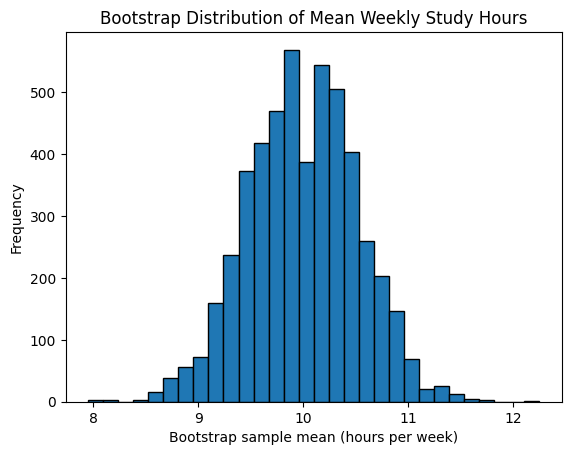

In [7]:
# Section 2, Q5
bootstrap_means = []

for i in range(5000):
    bootstrap_sample = rng.choice(
        study_hours,
        size=len(study_hours),
        replace=True
    )
    bootstrap_means.append(np.mean(bootstrap_sample))

print("Number of bootstrap means:", len(bootstrap_means))
print("Average bootstrap mean:",
      round(np.mean(bootstrap_means), 2), "hours")

plt.hist(bootstrap_means, bins=30, edgecolor="black")
plt.title("Bootstrap Distribution of Mean Weekly Study Hours")
plt.xlabel("Bootstrap sample mean (hours per week)")
plt.ylabel("Frequency")
plt.show()



### Q6. Construct a 95% Bootstrap Confidence Interval — 10 points

Use the bootstrap distribution from Q5.

For a 95% confidence interval, keep the **middle 95%** of the bootstrap distribution:

- Lower endpoint = **2.5th percentile**
- Upper endpoint = **97.5th percentile**

**a. (5 pts)** Calculate the confidence interval.  
**b. (3 pts)** Report the interval in a complete sentence.  
**c. (2 pts)** Explain what the confidence interval tells us that the point estimate alone does not.

In [8]:
# Section 2, Q6
lower, upper = np.percentile(bootstrap_means, [2.5, 97.5])

print("95% confidence interval:", (lower, upper))
print(
    f"We are 95% confident that the true mean weekly study "
    f"time of all students at the university is between "
    f"{lower:.2f} and {upper:.2f} hours."
)

95% confidence interval: (np.float64(9.0), np.float64(11.0))
We are 95% confident that the true mean weekly study time of all students at the university is between 9.00 and 11.00 hours.


The point estimate gives a single estimated population mean of 10 hours per week. The confidence interval provides a range of plausible values for the population mean and shows the uncertainty caused by sampling. A narrower interval indicates greater precision.

### Q7. Understanding 95% Confidence — 5 points

Which statement best describes **95% confidence**?

**A.** There is a 95% probability that the particular interval we calculated contains the parameter.  
**B.** 95% of individual students have study hours inside the confidence interval.  
**C.** If we repeatedly took random samples and constructed intervals using the same method, about 95% of those intervals would contain the true population parameter.  
**D.** 95% of bootstrap samples are identical to the original sample.

Write the correct letter and briefly explain your choice.

**Answer:
**Q7 — Understanding 95% Confidence**

Enter this in the text cell under Q7:

> C

The 95% describes the long-run success rate of the interval method. It does not mean that 95% of individual students study within this interval.

# Section 3 — Formulating a Hypothesis Test (20 points)

A coin is flipped **25 times**. We observe:

- **21 Heads**
- **4 Tails**

We want to investigate whether the coin is fair.

Let \(P\) represent the true probability of obtaining a head.

### Q8. Null and Alternative Hypotheses — 6 points

Write the hypotheses for a **two-sided test of coin fairness**.

**H₀:** P = 0.5. The coin is fair: the true probability of obtaining a head is 0.5.______________________________ — **3 pts**

**Hₐ:** P ≠ 0.5. The coin is unfair: the true probability of obtaining a head differs from 0.5.______________________________ — **3 pts**

### Q9. Statistic from the Sample — 4 points

Calculate the observed proportion of heads H/n:


Then explain why this value is a **statistic** rather than a parameter.

**Calculation — 2 pts**  
**Explanation — 2 pts**

In [9]:
# Section 3, Q9
heads = 21
n_flips = 25

observed_proportion = heads / n_flips

print("Observed proportion of heads:", observed_proportion)

Observed proportion of heads: 0.84


The observed proportion of 0.84 is a statistic because it is calculated from a sample of 25 coin flips. It estimates the coin’s true probability of heads, which is the population parameter.

### Q10. Test Statistic — 10 points

If the coin is fair, the expected number of heads in 25 flips is:

\[
25(0.5)=12.5
\]

Use the test statistic:

\[
T = |H - 12.5|
\]

**a. (3 pts)** Calculate the observed test statistic for **21 heads**.  
**b. (4 pts)** Calculate \(T\) for **13, 16, 21, and 4 heads**.  
**c. (3 pts)** Explain why a **larger value of T** provides stronger evidence against \(H₀\).

In [10]:
# Part a
# Section 3, Q10

# Part a
expected_heads = 25 * 0.5
observed_T = abs(21 - expected_heads)

print("Observed test statistic:", observed_T)

# Part b
head_counts = np.array([13, 16, 21, 4])
T_values = np.abs(head_counts - expected_heads)

for h, t in zip(head_counts, T_values):
    print(f"Heads: {h}, T: {t}")

Observed test statistic: 8.5
Heads: 13, T: 0.5
Heads: 16, T: 3.5
Heads: 21, T: 8.5
Heads: 4, T: 8.5


A larger value of T means the observed head count is farther from what is expected under the fair-coin hypothesis. Such large deviations are less likely if the coin is fair, so they provide stronger evidence against H₀. The absolute value treats deviations toward heads and tails equally.

# Section 4 — Null Simulation and p-values (40 points)

Under the null hypothesis, the coin is fair:

\[
P(Head)=0.5
\]

We can repeatedly simulate the experiment under \(H₀\) to create an **empirical null distribution**.

### Q11. Simulate the Experiment Under \(H₀\) — 10 points

Simulate **10,000 experiments**.

Each experiment consists of **25 flips of a fair coin**.

For every simulated experiment:

1. Record the number of heads.
2. Calculate the test statistic:

\[
T=|H-12.5|
\]

Store the simulated head counts in `simulated_heads` and the test statistics in `simulated_T`.

**Scoring:** Correct null model **3 pts**; repeated simulation **4 pts**; correct test statistic **3 pts**.

In [11]:
# Section 4, Q11
n_simulations = 10_000

simulated_heads = rng.binomial(
    n=25,
    p=0.5,
    size=n_simulations
)

simulated_T = np.abs(simulated_heads - 12.5)

print("Number of experiments:", len(simulated_heads))
print("First 10 head counts:", simulated_heads[:10])
print("First 10 test statistics:", simulated_T[:10])

Number of experiments: 10000
First 10 head counts: [13 11 10 12 13 14 14 15 14 14]
First 10 test statistics: [0.5 1.5 2.5 0.5 0.5 1.5 1.5 2.5 1.5 1.5]


### Q12. Visualize the Empirical Null Distribution — 10 points

Create a histogram of `simulated_T`.

Add a vertical line showing the **observed test statistic** for 21 heads.

Your graph should contain:

- Histogram of simulated test statistics — **4 pts**
- Vertical line for observed \(T\) — **2 pts**
- Meaningful title and axis labels — **4 pts**

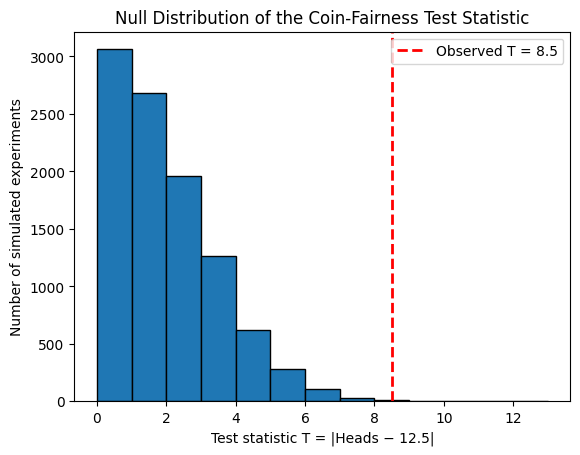

In [12]:
# Section 4, Q12
plt.hist(
    simulated_T,
    bins=np.arange(0, 14, 1),
    edgecolor="black"
)

plt.axvline(
    observed_T,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed T = {observed_T}"
)

plt.title("Null Distribution of the Coin-Fairness Test Statistic")
plt.xlabel("Test statistic T = |Heads − 12.5|")
plt.ylabel("Number of simulated experiments")
plt.legend()
plt.show()

### Q13. Calculate the Simulation-Based p-value — 10 points

The p-value can be estimated as the proportion of simulated test statistics that are **at least as extreme as the observed statistic**:

Calculate the simulation-based p-value.

In [13]:
# Section 4, Q13
extreme = simulated_T >= observed_T
p_value = np.mean(extreme)

print("Number of extreme outcomes:", np.sum(extreme))
print("Total simulations:", len(simulated_T))
print("Simulated p-value:", p_value)

Number of extreme outcomes: 10
Total simulations: 10000
Simulated p-value: 0.001


### Q14. Decision and Interpretation — 10 points

Use **α = 0.05**.

**a. (4 pts)** Compare the p-value with α.  
**b. (2 pts)** Should you **reject \(H₀\)** or **fail to reject \(H₀\)**?  
**c. (4 pts)** Write your conclusion in the context of the coin.

**Answer:**

# Section 5 — Statistical Errors and Critical Thinking (15 points)

### Q15. Type I and Type II Errors — 8 points

Consider the coin-fairness hypothesis test.

**a. (4 pts)** Describe a **Type I error** in the context of this experiment.

**b. (4 pts)** Describe a **Type II error** in the context of this experiment.

Do not provide only the generic definitions. Explain what each error would mean for the coin.

**Type I error:**  

**Type II error:**

### Q16. Interpreting a p-value — 7 points

A student says:

> **“Our p-value is 0.02, so there is only a 2% chance that the null hypothesis is true.”**

**a. (2 pts)** Is this interpretation correct?  
**b. (5 pts)** Rewrite the statement so that it correctly explains what a p-value of 0.02 means.

**Answer:**

---

# Assignment Point Summary

| Section | Topic | Points |
|---|---|---:|
| 1 | Parameters, Statistics & Descriptive Estimation | 20 |
| 2 | Bootstrapping & Confidence Intervals | 30 |
| 3 | Formulating a Hypothesis Test | 20 |
| 4 | Null Simulation & p-values | 40 |
| 5 | Statistical Errors & Critical Thinking | 15 |
| **Total** | | **125** |

## Submission Checklist

- [ ] All questions are answered.
- [ ] All code cells run without errors.
- [ ] Graphs include meaningful titles and axis labels.
- [ ] Hypotheses are stated clearly.
- [ ] Statistical conclusions are written in context.
- [ ] Notebook is saved with all outputs visible.